# Can AI Traverse the "Right" Graph of Research Conversations?

**Prototype for a proposal to the *AI-Enabled Frontiers in Organization Science* Special Issue.**

Claim under test: retrieval by semantic similarity (the basis of LLM literature tools) misidentifies research conversations, because conversations are constituted socially (who works with/for/alongside whom), not only lexically or semantically.

---

Design overview: Within a keyword frame (e.g. papers in the corpus containing the root *technolog\_* in the abstract), we draw paper pairs under different retrieval conditions and ask a domain expert whether each pair belongs to the same research conversation. The outcome is the **precision** of each condition: the share of pairs judged, by a human, to be in  the "same conversation".


The notebook executes two designs, selected by `DESIGN` in the configuration.

**Prototype** (`DESIGN = "prototype"`, 10 pairs per cell, 30 per frame track): three retrieval strategies, sampled directly.

| cell | how the pair is drawn | stands in for |
|---|---|---|
| `L0` | two random papers from the keyword frame | lexical search (database keyword search) |
| `T1` | same BERTopic topic, community unconstrained | **semantic search (the LLM view)** |
| `T1C1` | same topic, same coauthor community | socio-semantic search |

Expert judgments supply the fourth, pragmatic layer: standpoint, timing and the politics of citation, which no cell can sample. In the full design, disagreement among coders is treated as evidence of that layer.

Note: The prototype shows direction and effect size, with intervals, plus qualitative cases. It is not a confirmatory test.

- **Prototype Data:** Abstracts, titles, authors (+ Journal metadata) of ALL peer-reviewed publications between 2000 and 2023, inclusive, in Academy of Management Journal, Academy of Management Review, Administrative Science Quarterly, Information and Organization, Information Systems Research, Journal of Applied Psychology, Journal of International Business Studies, Journal of Management, Journal of Management Inquiry, Journal of Management Studies, Journal of Organizational Behavior, Journal of Strategic Information Systems, Management Information Systems Quarterly, Organizational Behavior and Human Decision Processes, **Organization Science**, Organization Studies, Research Policy, Strategic Management Journal, Strategic Organization, and Technological Forecasting and Social Change.





**Full design** (`DESIGN = "full"`, the Stage 2 test). It samples a 2×2 of topic × community plus the keyword baseline, and derives the deployed strategies from those cells. The full study scales the prototype on three axes:
- **Cells:** all five sampled cells, with about 30 pairs each, plus the derived `T1` and `C1` strategies.
- **Tracks and coders:** more keyword frame tracks, each labeled by several expert coders. We will recruit 10–20 tenure-track faculty, which lets us measure and relate coders' judgments to their own positions in the field.
- **Data:** a deeper and wider corpus, with more journals and adjacent fields, a longer time span, plus: foundational citation patterns, and academic lineage data alongside coauthorship in select sectors of the map.


**Sampled cells** (labeled by experts):

| cell | how the pair is drawn | role |
|---|---|---|
| `L0` | two random papers from the keyword frame | lexical search |
| `T0C0` | different topics, different coauthor communities | control |
| `T1C0` | same BERTopic topic, different community | semantic match, cross-community (contrast) |
| `T0C1` | different topics, same community | social match, cross-topic (contrast) |
| `T1C1` | same topic, same community | socio-semantic search |

**Derived retrieval strategies** (estimated from the cells above; no extra labels needed):

| strategy | definition | estimator |
|---|---|---|
| `T1` | same topic, community unconstrained: **semantic search (the LLM view)** | w·p(T1C1) + (1−w)·p(T1C0), where w is the same-community share of eligible same-topic pairs |
| `C1` | same community, topic unconstrained: social retrieval | v·p(T1C1) + (1−v)·p(T0C1), where v is the same-topic share of eligible same-community pairs |

General purpose LLM-based semantic search, in principle, does not account for communities, so the better estimand is `T1`, not `T1C0`. The 2×2 lets us separate the two signals; the derived rows give the precision each retrieval strategy would actually deliver.

Topics come from BERTopic over sentence embeddings of the full corpus. No topic is pre-selected as "about" the keyword: `T1` means same topic with both papers in the keyword frame, which is what semantic retrieval does with a keyword query. (A "top-words" rule is available as a robustness check: to see if the keywords appear in the topic's TF-IDF top terms) Communities come from Leiden clustering of the full-corpus coauthor network. A paper's community is the plurality community of its authors.

Key contrasts:
- Prototype: `T1` vs `T1C1` (does adding social structure to semantic retrieval raise precision?) and `L0` vs `T1`.
- Full design: the three below.
- `T1C0` vs `T1C1`: the social signal, with text held constant.
- `T1` vs `C1`: semantic against social retrieval, as each would be deployed.
- `L0` vs `T1`: does semantic retrieval beat keyword search at all?

Test safeguards:
- No pair shares an author. (To be interrogated in the Full design).
- No paper appears in more than one pair, across both tracks, so the pairs are independent observations.
- Labelers are blind to condition: pairs are shuffled into one sheet, and the cell key is kept in a separate file.
- Pairs are drawn uniformly from each cell's eligible pairs. In the full design this matches the pair-weighted mixing weights.
- The network and the topic model are fitted on the full corpus, not on the keyword frame.

**Protoype: Two tracks run in parallel:** `knowledge` (labeled by author1) and `technology` (labeled by author2).

This is a pilot: unsupervised partitions plus a small expert-labeled sample, from two coders on two tracks of a 20-journal corpus. Its results are evidence for the proposal's feasibility and direction, not the test itself.

## 0. Setup

In [1]:
import re, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, CACHE, OUT, LABELS = (ROOT / d for d in ("data", "cache", "outputs", "labels"))
for d in (CACHE, OUT, LABELS):
    d.mkdir(exist_ok=True)

SEED = 20261101
rng = np.random.default_rng(SEED)
pd.set_option("display.max_colwidth", 120)

### Configuration
Analytic details/choices here. `lexical` is matched against title + abstract and defines the keyword frame.

`TOPIC_RULE` decides which topics can feed the `T1` cells:
- `"all"` (primary): any non-outlier topic. It needs no thresholds and treats both tracks the same way. The keyword frame already guarantees relevance.
- `"top_words"` (robustness): only topics whose top c-TF-IDF terms contain the track's stem (`topic_word`). It works for concepts that form their own cluster, such as technology (10 topics). It fails for dispersed ones: expertise gets 0 topics, which is itself a finding.

`DESIGN` selects which cells are sampled and how many pairs each gets. The analysis runs only what those cells support: the derived strategies and the 2×2 regression need the full design.

The topic model is cached separately for each (`MIN_CLUSTER_SIZE`, `MIN_SAMPLES`) setting. Changing them refits the model without overwriting the earlier run, so both granularities stay available for the robustness check in section 9.

In [2]:
TRACKS = {
    "knowledge":  dict(lexical=r"\bknow",   topic_word=r"know",   labeler="author1"),
    "technology": dict(lexical=r"\btechnolog", topic_word=r"technolog", labeler="author2"),
}

TOPIC_RULE         = "all"         # "all" (primary) | "top_words" (robustness)

# frame filters, applied to both tracks (None = no filter)
YEAR_MIN, YEAR_MAX = 2000, 2023
MIN_CITES          = None          # if we want to only look at "significat" papers in some sense
EXCLUDE_JOURNALS   = ["tfsc"]            # is we want to deliberately exclude some journals (e.g. futurist journals from the technolog_ track

DESIGN             = "prototype"   # "prototype" (3 cells x 10) | "full" (5 cells x 30 + derived strategies)
DESIGNS = {
    "prototype": dict(
        cells=["T1C1", "T1", "L0"],                        # sampling order: scarce cells first
        n={"T1C1": 10, "T1": 10, "L0": 10},
        ladder={"L0": 0, "T1": 1, "T1C1": 2},              # predicted precision order (trend test)
        contrasts=[("T1", "T1C1"), ("L0", "T1")],          # (lower, higher)
        derived=False),
    "full": dict(
        cells=["T1C1", "T0C1", "T1C0", "T0C0", "L0"],
        n={"T1C1": 30, "T0C1": 30, "T1C0": 30, "T0C0": 30, "L0": 30},
        ladder={"L0": 0, "T1C0": 1, "T0C1": 2, "T1C1": 3},
        contrasts=[("T1C0", "T1C1"), ("T1C0", "T0C1"), ("T1", "C1"), ("L0", "T1")],
        derived=True),
}
CELLS, N_PAIRS, LADDER = (DESIGNS[DESIGN][k] for k in ("cells", "n", "ladder"))

# embeddings + topic model
EMBED_MODEL        = "sentence-transformers/all-mpnet-base-v2"  # general-purpose; NOT SPECTER (citation-trained)
EMBED_BATCH        = 64
UMAP_KW            = dict(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine")
MIN_CLUSTER_SIZE   = 20            # smaller -> more, finer topics. for ref. minsize 40 yields around 130 topics on this corpus.
MIN_SAMPLES        = 5             # smaller -> fewer outliers
TOP_N_WORDS        = 10
REFIT_TOPICS       = False         # True = refit even if this setting is cached

# coauthor network
LEIDEN_RESOLUTION  = 1.0           # higher = smaller communities; report results at >1 resolution

# labeling sheet
SHOW_AUTHORS       = False         # showing authors leaks a social signal to the labeler. Design choice for "full" version.

In [3]:
import torch
DEVICE = ("mps" if torch.backends.mps.is_available()
          else "cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

device: mps


## 1. Data

In [4]:
papers = pd.read_parquet(DATA / "papers.parquet")
auth   = pd.read_parquet(DATA / "authorships.parquet")
papers["text"] = (papers["title"].str.strip() + ". " + papers["abstract"]).str.strip()
papers = papers.set_index("paper_id", drop=False)

authors_of = auth.groupby("paper_id")["author_id"].agg(frozenset).to_dict()
print(f"{len(papers):,} papers | {papers.has_abstract.sum():,} with abstracts | "
      f"{auth.author_id.nunique():,} authors | {papers.journal.nunique()} journals")
papers.groupby("journal").size().sort_values(ascending=False).to_frame("n").T

28,620 papers | 27,955 with abstracts | 35,476 authors | 20 journals


journal,tfsc,rp,jap,smj,osc,ost,amj,jm,job,jms,obhdp,jibs,isr,misq,jmi,amr,so,asq,jsis,ino
n,5489,3020,2283,1994,1550,1527,1475,1399,1347,1331,1232,1207,986,780,772,590,473,464,395,306


## 2. Embeddings
Title + abstract, L2-normalized, cached to `cache/`. 

In [5]:
docs_df = papers[papers.has_abstract]
doc_ids = docs_df.paper_id.tolist()
docs    = docs_df.text.tolist()

emb_path = CACHE / f"emb_{EMBED_MODEL.split('/')[-1]}.npz"
if emb_path.exists():
    z = np.load(emb_path, allow_pickle=True)
    assert z["paper_id"].tolist() == doc_ids, "embedding cache does not match corpus; delete it"
    emb = z["emb"]
else:
    from sentence_transformers import SentenceTransformer
    st = SentenceTransformer(EMBED_MODEL, device=DEVICE)
    emb = st.encode(docs, batch_size=EMBED_BATCH, show_progress_bar=True,
                    normalize_embeddings=True, convert_to_numpy=True)
    np.savez_compressed(emb_path, emb=emb, paper_id=np.array(doc_ids, dtype=object))
row_of = {pid: i for i, pid in enumerate(doc_ids)}
print(emb.shape)

(27955, 768)


## 3. Topic model (BERTopic, full corpus)
The model is fitted once on all abstracts and cached for each (`MIN_CLUSTER_SIZE`, `MIN_SAMPLES`) setting. HDBSCAN outliers (topic −1) are excluded from the topic cells. Expect about 5 minutes on Apple silicon, most of it UMAP; the fixed `random_state` makes UMAP single-threaded.

In [6]:
TOPIC_TAG = f"mcs{MIN_CLUSTER_SIZE}_ms{MIN_SAMPLES}"
topics_path, words_path = CACHE / f"topics_{TOPIC_TAG}.parquet", CACHE / f"topic_words_{TOPIC_TAG}.json"

if topics_path.exists() and words_path.exists() and not REFIT_TOPICS:
    topic_assign = pd.read_parquet(topics_path).set_index("paper_id")["topic"]
    topic_words  = {int(k): v for k, v in json.loads(words_path.read_text()).items()}
    topic_model  = None
else:
    from bertopic import BERTopic
    from bertopic.vectorizers import ClassTfidfTransformer
    from umap import UMAP
    from hdbscan import HDBSCAN
    from sklearn.feature_extraction.text import CountVectorizer

    topic_model = BERTopic(
        embedding_model=None,   # embeddings are precomputed
        umap_model=UMAP(random_state=SEED, **UMAP_KW),
        hdbscan_model=HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, min_samples=MIN_SAMPLES,
                              metric="euclidean", cluster_selection_method="eom", prediction_data=True),
        vectorizer_model=CountVectorizer(stop_words="english", ngram_range=(1, 2), min_df=5),
        ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True),
        top_n_words=TOP_N_WORDS, calculate_probabilities=False, verbose=True,
    )
    topics, _ = topic_model.fit_transform(docs, embeddings=emb)
    topic_assign = pd.Series(topics, index=doc_ids, name="topic")
    topic_words  = {int(t): [w for w, _ in topic_model.get_topic(t)]
                    for t in topic_model.get_topics() if t != -1}
    topic_assign.rename_axis("paper_id").reset_index().to_parquet(topics_path, index=False)
    words_path.write_text(json.dumps(topic_words))

papers["topic"] = topic_assign.reindex(papers.index).fillna(-1).astype(int)
topic_size = papers.loc[papers.topic != -1, "topic"].value_counts()
print(f"[{TOPIC_TAG}] {len(topic_words)} topics | outliers: {(papers.topic == -1).mean():.1%} of papers | "
      f"median topic size: {topic_size.median():.0f}")

[mcs20_ms5] 290 topics | outliers: 35.7% of papers | median topic size: 44


## 4. Coauthor network and communities (full corpus)
Authors are nodes. Edge weight is the number of coauthored papers. Communities come from Leiden (RB-configuration / modularity). Authors who never coauthor end up as singleton communities, so their papers can never fall into a `C1` cell.

In [7]:
import igraph as ig
import leidenalg as la

pa = auth[["paper_id", "author_id"]]
co = pa.merge(pa, on="paper_id").query("author_id_x < author_id_y")
w  = co.groupby(["author_id_x", "author_id_y"]).size().rename("weight").reset_index()

author_index = pd.Index(pa.author_id.unique())
g = ig.Graph(n=len(author_index),
             edges=list(zip(author_index.get_indexer(w.author_id_x),
                            author_index.get_indexer(w.author_id_y))))
g.es["weight"] = w.weight.tolist()

part = la.find_partition(g, la.RBConfigurationVertexPartition, weights="weight",
                         resolution_parameter=LEIDEN_RESOLUTION, seed=SEED)
author_comm = pd.Series(part.membership, index=author_index)
comm_n_auth = author_comm.value_counts()

# paper -> plurality community of its authors (ties -> larger community)
pa_c = pa.assign(comm=pa.author_id.map(author_comm))
def _plurality(s):
    vc = s.value_counts()
    return max(vc[vc == vc.max()].index, key=lambda c: comm_n_auth[c])
papers["comm"] = pa_c.groupby("paper_id")["comm"].agg(_plurality).reindex(papers.index)
papers["comm_purity"] = (pa_c.groupby("paper_id")["comm"]
                         .agg(lambda s: s.value_counts(normalize=True).iloc[0]).reindex(papers.index))
comm_n_pap = papers.comm.value_counts()

giant = max(g.connected_components(), key=len)
print(f"{g.vcount():,} authors, {g.ecount():,} ties | giant component {len(giant)/g.vcount():.1%}")
print(f"{part.q:.3f} quality | {(comm_n_auth > 1).sum():,} non-singleton communities | "
      f"median papers/community (non-singleton): {comm_n_pap[comm_n_pap > 1].median():.0f}")

35,476 authors, 120,871 ties | giant component 67.9%
0.854 quality | 2,925 non-singleton communities | median papers/community (non-singleton): 2


## 5. Track frames and topic-relevant topics

In [8]:
base = papers.has_abstract & papers.year.between(YEAR_MIN, YEAR_MAX) & ~papers.journal.isin(EXCLUDE_JOURNALS)
if MIN_CITES is not None:
    base &= papers.cited_by.fillna(0) > MIN_CITES

def topic_profile(lex_mask):
    """Descriptive: per topic, how many keyword papers it holds and how concentrated they are."""
    B = papers[base & (papers.topic != -1)]
    in_lex = lex_mask.reindex(B.index)
    g = pd.DataFrame({"size": B.groupby("topic").size(), "in_frame": in_lex.groupby(B.topic).sum()})
    g["share"] = g.in_frame / g["size"]
    g["lift"]  = g.share / in_lex.mean()
    g["top_words"] = [", ".join(topic_words.get(t, [])[:8]) for t in g.index]
    return g.sort_values("in_frame", ascending=False)

def pick_topics(cfg, prof):
    if TOPIC_RULE == "top_words":
        wrx = re.compile(cfg["topic_word"], re.I)
        return sorted(t for t, ws in topic_words.items() if any(wrx.search(x) for x in ws))
    if TOPIC_RULE == "all":
        return sorted(prof.index[prof.in_frame >= 1])
    raise ValueError(f"unknown TOPIC_RULE {TOPIC_RULE!r}")

frames, PROFILE = {}, {}
for track, cfg in TRACKS.items():
    rx = re.compile(cfg["lexical"], re.I)
    lex = base & (papers.title.str.contains(rx) | papers.abstract.str.contains(rx))
    prof = topic_profile(lex)
    ttopics = pick_topics(cfg, prof)
    prof["selected"] = prof.index.isin(ttopics)
    PROFILE[track] = prof
    F  = papers[lex]
    FT = F[F.topic.isin(ttopics)]
    frames[track] = dict(F=F, FT=FT, topics=ttopics)
    n_pair_topics = int((FT.groupby("topic").size() >= 2).sum())
    print(f"\n=== {track}: {len(F):,} papers in keyword frame | rule={TOPIC_RULE} | {len(ttopics)} topics "
          f"({n_pair_topics} with >=2 frame papers) | {len(FT):,} frame papers usable "
          f"({len(FT) / max(len(F), 1):.0%}) | outliers in frame: {(F.topic == -1).mean():.0%} "
          f"(corpus: {(papers.topic == -1).mean():.0%})")
    top10 = prof.in_frame.head(10).sum() / max(prof.in_frame.sum(), 1)
    print(f"    concentration: top-10 topics hold {top10:.0%} of the frame's non-outlier papers")
    if len(ttopics) < 2:
        warnings.warn(f"{track}: fewer than 2 relevant topics; T0 cells will draw different-topic pairs "
                      f"from the whole keyword frame instead.")


=== knowledge: 4,336 papers in keyword frame | rule=all | 260 topics (239 with >=2 frame papers) | 2,682 frame papers usable (62%) | outliers in frame: 38% (corpus: 36%)
    concentration: top-10 topics hold 20% of the frame's non-outlier papers

=== technology: 3,578 papers in keyword frame | rule=all | 220 topics (171 with >=2 frame papers) | 2,207 frame papers usable (62%) | outliers in frame: 38% (corpus: 36%)
    concentration: top-10 topics hold 33% of the frame's non-outlier papers


### Where each frame's papers sit across topics
A descriptive table (NOT selection step): the 20 topics that hold the most keyword papers. A clustered concept piles into a few high-lift topics; a dispersed one spreads thinly across many low-lift ones. Compare the two tracks' concentration lines above; the difference belongs in the paper.

In [9]:
for track, prof in PROFILE.items():
    print(f"=== {track}")
    display(prof.head(20).round({"share": 3, "lift": 1}))

=== knowledge


,size,in_frame,share,lift,top_words,selected
topic,,,,,,
1,324,90,0.278,1.5,"alliance, alliances, strategic alliances, partner, partners, alliance partners, rd alliances, alliance formation",True
0,331,68,0.205,1.1,"creativity, creative, team creativity, employee creativity, creative performance, individual creativity, creative pr...",True
14,138,56,0.406,2.3,"technology transfer, university, universities, universityindustry, commercialization, transfer, university technolog...",True
52,83,55,0.663,3.7,"online communities, wikipedia, communities, community, online community, online, knowledge collaboration, contributors",True
55,84,52,0.619,3.4,"overseas, ipr, rd activities, subsidiaries, japanese, rd, host, affiliates",True
7,202,52,0.257,1.4,"phd, scientists, interdisciplinary research, research productivity, funding, interdisciplinary, coauthors, faculty",True
38,84,49,0.583,3.2,"regional, regions, regional innovation, inventors, geography, spatial, spatial distribution, metropolitan",True
118,50,45,0.900,5.0,"communities practice, knowledge management, km, organizational knowledge, knowing, kms, knowledge knowledge, knowled...",True
8,205,41,0.200,1.1,"team, team performance, teams, teamwork, team effectiveness, team processes, team learning, collective efficacy",True


=== technology


,size,in_frame,share,lift,top_words,selected
topic,,,,,,
17,162,103,0.636,4.3,"alignment, strategic alignment, information technology, cio, information systems, itenabled, strategic information, ...",True
18,167,93,0.557,3.8,"information systems, sociomateriality, systems research, critical realism, sociomaterial, realism, affordances, disc...",True
1,324,89,0.275,1.9,"alliance, alliances, strategic alliances, partner, partners, alliance partners, rd alliances, alliance formation",True
23,130,76,0.585,4.0,"incumbents, incumbent, entrants, entry, repositioning, old technology, complementary assets, entrant",True
14,138,66,0.478,3.2,"technology transfer, university, universities, universityindustry, commercialization, transfer, university technolog...",True
21,127,63,0.496,3.4,"patent, litigation, patents, examiners, patent litigation, prior art, ip, patent value",True
2,108,62,0.574,3.9,"transitions, sociotechnical, sustainability transitions, wind, transition, policy mixes, mixes, sociotechnical trans...",True
59,77,62,0.805,5.4,"technology acceptance, acceptance, usage, ease use, postadoption, behavioral intention, disconfirmation, technology use",True
12,90,61,0.678,4.6,"innovation policy, science technology, national innovation, economic growth, innovation policies, technology upgradi...",True


## 6. Pair sampling
For each cell we build the eligible candidate pairs. Same-topic and same-community cells enumerate every pair within their groups; the other cells use random draws filtered by the cell's condition. Pairs are then taken in uniformly random order, so each eligible pair has the same chance of selection, and a big topic contributes in proportion to the pairs it holds. Two constraints apply during selection:
- Each paper is used at most once, across both tracks.
- Pairs sharing any author are rejected.

Each cell is specified as (same topic?, same community?). `None` means unconstrained, so `T1` is (1, None) and `L0` is (None, None).

In [10]:
def _within(idx_groups, cap=4000):
    out = []
    for ids in idx_groups:
        ids = np.asarray(ids)
        if len(ids) < 2:
            continue
        if len(ids) > cap:   # keeps memory bounded; slightly under-weights that group
            warnings.warn(f"group of {len(ids)} papers subsampled to {cap} for pair enumeration")
            ids = rng.choice(ids, cap, replace=False)
        i, j = np.triu_indices(len(ids), 1)
        out.append(np.c_[ids[i], ids[j]])
    return np.vstack(out) if out else np.empty((0, 2), dtype=int)

def _random(n, k):
    a, b = rng.integers(0, n, k), rng.integers(0, n, k)
    keep = a != b
    return np.c_[np.minimum(a, b), np.maximum(a, b)][keep]

# (same topic, same community); None = unconstrained
SPEC = {"L0": (None, None), "T1": (1, None), "C1": (None, 1),
        "T1C1": (1, 1), "T1C0": (1, 0), "T0C1": (0, 1), "T0C0": (0, 0)}

def candidates(cell, F, FT, has_topics):
    """Return (pool dataframe, array of positional pairs, stratum per pair)."""
    st, sc = SPEC[cell]
    if st is None and sc is None:                      # keyword only
        pool = F.reset_index(drop=True)
        prs = np.unique(_random(len(pool), 200_000), axis=0)
        return pool, prs, np.zeros(len(prs), dtype=int)

    pool = (FT if (st == 1 or has_topics) else F[F.topic != -1]).reset_index(drop=True)
    t, c = pool.topic.to_numpy(), pool.comm.to_numpy()

    if sc == 1:
        keys = ["topic", "comm"] if st == 1 else ["comm"]
        prs = _within(pool.groupby(keys).indices.values())
    elif st == 1:
        prs = _within(pool.groupby("topic").indices.values())
    else:
        prs = np.unique(_random(len(pool), 300_000), axis=0)
    if len(prs):
        a, b = prs[:, 0], prs[:, 1]
        ok = np.ones(len(prs), dtype=bool)
        if st is not None:
            ok &= (t[a] == t[b]) == bool(st)
        if sc is not None:
            ok &= (c[a] == c[b]) == bool(sc)
        prs = prs[ok]
    return pool, prs, np.zeros(len(prs), dtype=int)   # single stratum = uniform over eligible pairs

def select(pool, prs, strata, n, used):
    pid = pool.paper_id.to_numpy()
    order = rng.permutation(len(prs))
    buckets = {}
    for k in order:
        buckets.setdefault(strata[k], []).append(k)
    queues = {s: iter(v) for s, v in buckets.items()}
    chosen = []
    while len(chosen) < n and queues:
        for s in list(queues):
            for k in queues[s]:
                a, b = pid[prs[k, 0]], pid[prs[k, 1]]
                if a in used or b in used or (authors_of.get(a, frozenset()) & authors_of.get(b, frozenset())):
                    continue
                chosen.append((a, b)); used.update((a, b))
                break
            else:
                del queues[s]
                continue
            if len(chosen) >= n:
                break
    return chosen

used, rows, feas = set(), [], []
for track, fr in frames.items():
    has_topics = len(fr["topics"]) >= 2
    for cell in CELLS:
        pool, prs, strata = candidates(cell, fr["F"], fr["FT"], has_topics)
        chosen = select(pool, prs, strata, N_PAIRS[cell], used)
        feas.append(dict(track=track, cell=cell, pool_papers=len(pool),
                         eligible_pairs=len(prs), strata=len(set(strata)), sampled=len(chosen)))
        rows += [dict(track=track, cell=cell, paper_a=a, paper_b=b) for a, b in chosen]

feas = pd.DataFrame(feas)
display(feas.pivot(index="cell", columns="track", values=["eligible_pairs", "sampled"]).loc[CELLS])
short = feas[feas.sampled < feas.cell.map(N_PAIRS)]
if len(short):
    warnings.warn("Under-filled cells:\n" + short.to_string(index=False))

eligible_pairs              sampled           
track      knowledge technology knowledge technology
cell                                                
T1C1            7204       9552        10         10
T1             30713      38907        10         10
L0            197831     196907        10         10

### Mixing weights for the derived strategies
- `w`: among all eligible same-topic pairs (topic-relevant topics, no shared author), the share that also share a community.
- `v`: among all eligible same-community pairs, the share that also share a topic.

These are exact counts over the pool, not estimates from the sample. Pairs that share an author are enumerated through the authorship table and subtracted. Both the weights and the cell sampling are uniform over eligible pairs, so the mixture is internally consistent.

In the prototype, `w` is descriptive: it is the share of semantic-retrieval (`T1`) pairs that happen to fall within one community. That is the gap the prototype contrast is about.

In [11]:
def _c2(n):
    n = np.asarray(n, dtype=float)
    return (n * (n - 1) / 2).sum()

def mixing_weights(pool):
    pool = pool[pool.comm.notna()]
    t, c = pool.set_index("paper_id").topic, pool.set_index("paper_id").comm
    # pairs within the pool that share >=1 author (excluded by design)
    sub = auth.loc[auth.paper_id.isin(pool.paper_id), ["paper_id", "author_id"]]
    sh = (sub.merge(sub, on="author_id").query("paper_id_x < paper_id_y")
             [["paper_id_x", "paper_id_y"]].drop_duplicates())
    st = t.loc[sh.paper_id_x].to_numpy() == t.loc[sh.paper_id_y].to_numpy()
    sc = c.loc[sh.paper_id_x].to_numpy() == c.loc[sh.paper_id_y].to_numpy()

    same_t    = _c2(pool.groupby("topic").size())          - st.sum()
    same_c    = _c2(pool.groupby("comm").size())           - sc.sum()
    same_tc   = _c2(pool.groupby(["topic", "comm"]).size()) - (st & sc).sum()
    return dict(w=same_tc / same_t if same_t else np.nan,
                v=same_tc / same_c if same_c else np.nan,
                pairs_same_topic=int(same_t), pairs_same_comm=int(same_c), pairs_both=int(same_tc))

MIX = {}
for track, fr in frames.items():
    pool = fr["FT"] if len(fr["topics"]) >= 2 else fr["F"][fr["F"].topic != -1]
    MIX[track] = mixing_weights(pool)
pd.DataFrame(MIX).T

,w,v,pairs_same_topic,pairs_same_comm,pairs_both
knowledge,0.222366,0.020414,30126.0,328155.0,6699.0
technology,0.233040,0.042606,38148.0,208656.0,8890.0


### Cosine similarity by cell
This table summarises the text similarity of each cell's sampled pairs. A step up from `L0` to `T1` is expected, because sharing a topic implies similar text. A further gap from `T1` to `T1C1` means coauthor communities share vocabulary. Text then carries some of the social signal, and a higher expert precision for `T1C1` could partly reflect closer text. The full design matches `T1` pairs to `T1C1` pairs on cosine similarity to rule this out.

In [12]:
S = pd.DataFrame(rows)
for side in ("a", "b"):
    p = papers.loc[S[f"paper_{side}"]]
    S[f"topic_{side}"] = p.topic.to_numpy()
    S[f"comm_{side}"]  = p.comm.to_numpy()
    S[f"comm_npapers_{side}"] = p.comm.map(comm_n_pap).to_numpy()
S["cosine"] = [float(emb[row_of[a]] @ emb[row_of[b]]) for a, b in zip(S.paper_a, S.paper_b)]
S["T"] = S.cell.map(lambda c: SPEC[c][0]).astype("Int64")   # None -> <NA>: unconstrained
S["C"] = S.cell.map(lambda c: SPEC[c][1]).astype("Int64")
S["same_comm_realized"] = (S.comm_a == S.comm_b)            # for T1 / L0: did the pair land in one community?

# blind IDs: shuffle within track
S = S.sample(frac=1, random_state=SEED).reset_index(drop=True)
S["pair_uid"] = S.groupby("track").cumcount().add(1).map("{:03d}".format)
S["pair_uid"] = S.track.str[:4] + "-" + S.pair_uid
S.to_parquet(OUT / "pair_sample.parquet", index=False)
S.groupby(["track", "cell"]).cosine.describe()[["count", "mean", "50%", "min", "max"]].round(3)

count   mean    50%    min    max
track      cell                                   
knowledge  L0     10.0  0.275  0.251  0.082  0.522
           T1     10.0  0.654  0.680  0.507  0.749
           T1C1   10.0  0.649  0.658  0.481  0.822
technology L0     10.0  0.336  0.331  0.087  0.610
           T1     10.0  0.621  0.636  0.478  0.719
           T1C1   10.0  0.518  0.496  0.380  0.686

### What the embedding sees
This plot shows the cosine similarity of each pair, by cell. Where same-topic cells (`T1`, and `T1C0` in the full design) overlap `T1C1` in similarity but experts still separate them, text similarity alone cannot tell the conversations apart. That is the core of the argument. The overlap is visible before any labels exist; the expert labels then show whether the separation holds.

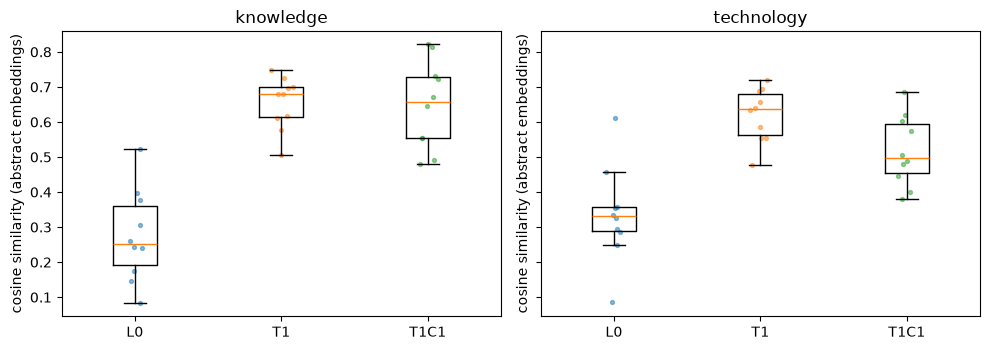

In [13]:
PLOT_CELLS = [c for c in ["L0", "T0C0", "T1", "T1C0", "T0C1", "T1C1"] if c in CELLS]
fig, axes = plt.subplots(1, len(TRACKS), figsize=(5 * len(TRACKS), 3.6), sharey=True)
for ax, track in zip(np.atleast_1d(axes), TRACKS):
    d = S[S.track == track]
    data = [d.loc[d.cell == c, "cosine"] for c in PLOT_CELLS]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, len(PLOT_CELLS) + 1), PLOT_CELLS)
    for i, v in enumerate(data, 1):
        ax.scatter(np.full(len(v), i) + rng.normal(0, .05, len(v)), v, s=8, alpha=.5)
    ax.set_title(track); ax.set_ylabel("cosine similarity (abstract embeddings)")
plt.tight_layout(); plt.savefig(OUT / "cosine_by_cell.png", dpi=200); plt.show()

## 7. Labeling sheets (blind)
Each track produces one sheet. Pair order is shuffled, and no cell, topic, community or similarity information appears on the sheet. The key goes to a separate file (`outputs/<track>_key.csv`). Labelers fill in `label`:
- `S`: same research conversation
- `D`: different conversations
- `U`: can't tell

Return the filled file to `labels/<track>_<labeler>.xlsx`. A second labeler on the same track can save `labels/<track>_<name>.xlsx`, and the analysis will report agreement.

In [14]:
INSTRUCTIONS = (
    "For each row, read both papers and judge whether they belong to the SAME RESEARCH CONVERSATION: "
    "a community of scholars engaging a shared problem, who would plausibly read, cite and respond to "
    "each other's work. Shared vocabulary or subject matter alone is not enough. "
    "label: S = same conversation, D = different, U = can't tell. "
    "confidence: 1 (guess) to 3 (certain). notes: optional, e.g. name the conversation(s)."
)

def paper_fields(pid, side):
    p = papers.loc[pid]
    f = {f"{side}_title": p.title, f"{side}_journal": p.journal.upper(), f"{side}_year": int(p.year)}
    if SHOW_AUTHORS:
        f[f"{side}_authors"] = "; ".join(auth.loc[auth.paper_id == pid].sort_values("position").author_name)
    f[f"{side}_abstract"] = p.abstract
    return f

for track, cfg in TRACKS.items():
    d = S[S.track == track].sort_values("pair_uid")
    sheet = pd.DataFrame([{"pair_uid": r.pair_uid, **paper_fields(r.paper_a, "A"),
                           **paper_fields(r.paper_b, "B"), "label": "", "confidence": "", "notes": ""}
                          for r in d.itertuples()])
    d.drop(columns=["T", "C"]).to_csv(OUT / f"{track}_key.csv", index=False)
    path = OUT / f"{track}_labeling_{cfg['labeler']}.xlsx"
    with pd.ExcelWriter(path, engine="openpyxl") as xw:
        sheet.to_excel(xw, sheet_name="pairs", index=False)
        pd.DataFrame({"instructions": [INSTRUCTIONS]}).to_excel(xw, sheet_name="instructions", index=False)
        ws = xw.sheets["pairs"]
        from openpyxl.styles import Alignment
        for col in ws.columns:
            name = col[0].value
            ws.column_dimensions[col[0].column_letter].width = (
                70 if name.endswith("abstract") else 40 if name.endswith("title") else 12)
            for c in col[1:]:
                c.alignment = Alignment(wrap_text=True, vertical="top")
        ws.freeze_panes = "B2"
    print(f"{track}: {len(sheet)} pairs -> {path.relative_to(ROOT)}")

knowledge: 30 pairs -> outputs/knowledge_labeling_author1.xlsx
technology: 30 pairs -> outputs/technology_labeling_author2.xlsx


## 8. Analysis
The analysis reads every `labels/<track>_*.xlsx|csv`. If no labels exist yet, it runs on **simulated** labels so the pipeline can be checked end to end. Every output from that run is stamped SIMULATED. Delete nothing; once real files appear in `labels/`, they are used instead.

In [21]:
def load_labels():
    frames_ = []
    for f in sorted(LABELS.glob("*_*.*")):
        if f.suffix not in (".xlsx", ".csv"):
            continue
        track, labeler = f.stem.split("_", 1)
        d = pd.read_excel(f) if f.suffix == ".xlsx" else pd.read_csv(f)
        keep = [c for c in ("pair_uid", "label", "confidence", "notes") if c in d.columns]
        frames_.append(d[keep].assign(track=track, labeler=labeler))
    return pd.concat(frames_, ignore_index=True) if frames_ else None

lab = load_labels()
SIMULATED = lab is None
if SIMULATED:
    warnings.warn("No files in labels/ — using SIMULATED labels. Results below are not data.")
    p_same = {"L0": .05, "T0C0": .05, "T1": .27, "T1C0": .25, "T0C1": .40, "T1C1": .65}
    lab = S[["pair_uid", "track", "cell"]].copy()
    lab["label"] = [rng.choice(["S", "D", "U"], p=[.95 * p_same[c], .95 * (1 - p_same[c]), .05])
                    for c in lab.cell]
    lab = lab.assign(labeler=lab.track.map({k: v["labeler"] for k, v in TRACKS.items()}))[
        ["pair_uid", "label", "track", "labeler"]].assign(confidence=np.nan, notes="")

lab["label"] = lab.label.astype(str).str.strip().str.upper().str[:1]
D = S.merge(lab, on=["pair_uid", "track"], how="inner")
D["y"] = D.label.map({"S": 1, "D": 0})
TAG = " [SIMULATED]" if SIMULATED else ""
print(f"{len(D)} labeled rows | unlabeled/U: {D.y.isna().sum()} "
      f"({D.label.eq('U').mean():.1%} 'can't tell')")

60 labeled rows | unlabeled/U: 4 (6.7% 'can't tell')


/var/folders/mn/bcsy_vn50gq966qwr12s8p800000gn/T/ipykernel_15477/1407294833.py:15: UserWarning: No files in labels/ — using SIMULATED labels. Results below are not data.
  warnings.warn("No files in labels/ — using SIMULATED labels. Results below are not data.")


In [22]:
from statsmodels.stats.proportion import proportion_confint
from scipy.stats import fisher_exact, norm

# primary labeler per track for the main estimates
prim = D[D.labeler == D.track.map({k: v["labeler"] for k, v in TRACKS.items()})].dropna(subset=["y"])

prec = (prim.groupby(["track", "cell"]).y.agg(k="sum", n="count").reset_index())
ci = proportion_confint(prec.k, prec.n, method="wilson")
prec["precision"], prec["lo"], prec["hi"] = prec.k / prec.n, ci[0], ci[1]
order = ["L0", "T0C0", "T1", "T1C0", "T0C1", "T1C1"]
prec["cell"] = pd.Categorical(prec.cell, order)
prec["kind"] = "sampled"
display(prec.sort_values(["track", "cell"]).round(3))

,track,cell,k,n,precision,lo,hi,kind
0,knowledge,L0,0.0,9,0.000,0.000,0.299,sampled
1,knowledge,T1,4.0,9,0.444,0.189,0.733,sampled
2,knowledge,T1C1,6.0,10,0.600,0.313,0.832,sampled
3,technology,L0,1.0,10,0.100,0.018,0.404,sampled
4,technology,T1,4.0,9,0.444,0.189,0.733,sampled
5,technology,T1C1,6.0,9,0.667,0.354,0.879,sampled


### Precision by cell, and derived strategies (full design only)
Every cell gets Jeffreys posterior draws, Beta(k+½, n−k+½), so cells with 0/n still carry uncertainty. In the full design, the derived strategies are mixtures of those draws. `T1` is semantic retrieval, w·p(T1C1) + (1−w)·p(T1C0); `C1` is social retrieval, v·p(T1C1) + (1−v)·p(T0C1). Because `w` is usually small, `T1` will sit close to `T1C0`. That is itself a finding: in this corpus, semantic retrieval mostly returns cross-community pairs. The prototype samples `T1` directly, so nothing is derived.

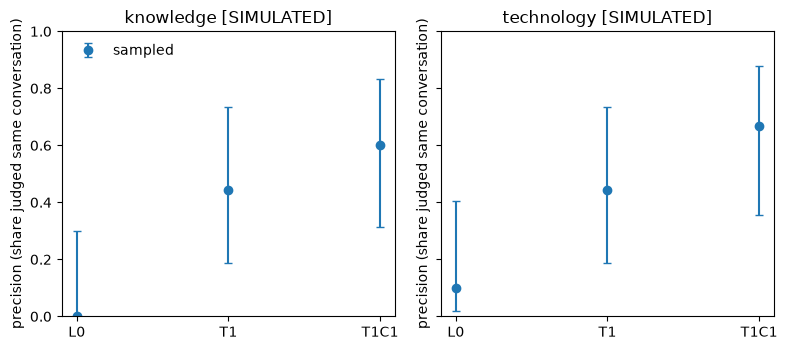

In [23]:
B = 20_000
def _draws(track, cell):
    r = prec[(prec.track == track) & (prec.cell == cell)]
    k, n = (int(r.k.iloc[0]), int(r.n.iloc[0])) if len(r) else (0, 0)
    return rng.beta(k + .5, n - k + .5, B), (k / n if n else np.nan)

DRAWS = {(t, c): _draws(t, c)[0] for t in TRACKS for c in CELLS}

DERIVED = []
if DESIGNS[DESIGN]["derived"]:
    for track in TRACKS:
        w, v = MIX[track]["w"], MIX[track]["v"]
        (d11, p11), (d10, p10), (d01, p01) = (_draws(track, c) for c in ("T1C1", "T1C0", "T0C1"))
        for name, wt, a_draw, a_pt, b_draw, b_pt in (("T1", w, d11, p11, d10, p10),
                                                      ("C1", v, d11, p11, d01, p01)):
            draws = wt * a_draw + (1 - wt) * b_draw
            DRAWS[(track, name)] = draws
            DERIVED.append(dict(track=track, cell=name, kind="derived", weight=wt,
                                precision=wt * a_pt + (1 - wt) * b_pt,
                                lo=np.quantile(draws, .025), hi=np.quantile(draws, .975)))
DERIVED = pd.DataFrame(DERIVED, columns=["track", "cell", "kind", "weight", "precision", "lo", "hi"])
if len(DERIVED):
    display(DERIVED.round(3))

# figure: sampled cells (filled) + derived strategies (open)
plot_order = [c for c in ["L0", "T0C0", "T1", "T1C0", "T0C1", "T1C1"] if c in CELLS]
n_sampled = len(plot_order)
plot_order += [c for c in ["T1", "C1"] if c in set(DERIVED.cell)]
allp = pd.concat([prec, DERIVED], ignore_index=True).astype({"cell": str})
fig, axes = plt.subplots(1, len(TRACKS), figsize=(max(4, 0.8 * len(plot_order)) * len(TRACKS), 3.6), sharey=True)
for ax, track in zip(np.atleast_1d(axes), TRACKS):
    d = allp[allp.track == track].drop_duplicates(["cell", "kind"]).set_index("cell")
    x = np.arange(len(plot_order))
    for kind, mfc, col in (("sampled", None, "C0"), ("derived", "white", "C1")):
        dk = d[d.kind == kind]
        xs = [i for i, c in enumerate(plot_order) if c in dk.index and (kind == "derived") == (i >= n_sampled)]
        if not xs:
            continue
        r = dk.loc[[plot_order[i] for i in xs]]
        yerr = np.clip([r.precision - r.lo, r.hi - r.precision], 0, None)   # Wilson bounds can overshoot by ~1e-17 at k=0
        ax.errorbar(xs, r.precision, yerr=yerr,
                    fmt="o", capsize=3, mfc=mfc, color=col, label=kind)
    if len(plot_order) > n_sampled:
        ax.axvline(n_sampled - .5, color="0.8", lw=.8)
    ax.set_xticks(x, plot_order); ax.set_ylim(0, 1)
    ax.set_title(track + TAG); ax.set_ylabel("precision (share judged same conversation)")
np.atleast_1d(axes)[0].legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.savefig(OUT / f"precision_by_cell_{DESIGN}{'_SIMULATED' if SIMULATED else ''}.png", dpi=200)
plt.show()

In [24]:
def fisher(track, c1, c2):
    d = prim[prim.track == track]
    t = [[d[(d.cell == c) & (d.y == 1)].shape[0], d[(d.cell == c) & (d.y == 0)].shape[0]] for c in (c1, c2)]
    odds, p = fisher_exact(t, alternative="less")   # H1: precision(c1) < precision(c2)
    return dict(track=track, contrast=f"{c1} < {c2}", table=t, odds_ratio=odds, p_one_sided=p)

def cochran_armitage(track):
    d = prim[(prim.track == track) & prim.cell.isin(LADDER)]
    g = d.groupby("cell").y.agg(["sum", "count"]).reindex(list(LADDER))
    s, x, n = np.array(list(LADDER.values()), float), g["sum"].to_numpy(float), g["count"].to_numpy(float)
    N, p = n.sum(), x.sum() / n.sum()
    T = np.sum(s * (x - n * p))
    var = p * (1 - p) * (np.sum(n * s**2) - np.sum(n * s) ** 2 / N)
    z = T / np.sqrt(var)
    return dict(track=track, contrast="trend " + " < ".join(LADDER), z=z, p_one_sided=norm.sf(z))

def derived_contrast(track, a, b):
    # posterior probability that precision(a) >= precision(b); small = evidence that a < b
    diff = DRAWS[(track, b)] - DRAWS[(track, a)]
    return dict(track=track, contrast=f"{a} < {b} (derived)", diff=float(np.median(diff)),
                diff_lo=float(np.quantile(diff, .025)), diff_hi=float(np.quantile(diff, .975)),
                p_one_sided=float((diff <= 0).mean()))

tests = []
for track in TRACKS:
    for a, b in DESIGNS[DESIGN]["contrasts"]:
        if a in CELLS and b in CELLS:
            tests.append(fisher(track, a, b))
        elif (track, a) in DRAWS and (track, b) in DRAWS:
            tests.append(derived_contrast(track, a, b))
    tests.append(cochran_armitage(track))
print("Hypothesis tests" + TAG)
pd.DataFrame(tests)

Hypothesis tests [SIMULATED]


,track,contrast,table,odds_ratio,p_one_sided,z
0,knowledge,T1 < T1C1,"[[4, 5], [6, 4]]",0.533333,0.414070,NaN
1,knowledge,L0 < T1,"[[0, 9], [4, 5]]",0.000000,0.041176,NaN
2,knowledge,trend L0 < T1 < T1C1,NaN,NaN,0.003423,2.704286
3,technology,T1 < T1C1,"[[4, 5], [6, 3]]",0.400000,0.318593,NaN
4,technology,L0 < T1,"[[1, 9], [4, 5]]",0.138889,0.119195,NaN
5,technology,trend L0 < T1 < T1C1,NaN,NaN,0.005612,2.535642


In [25]:
import statsmodels.formula.api as smf
import statsmodels.api as sm

# 2x2 cells only (full design): main effects of shared topic (T) and shared community (C), track fixed effect
if not DESIGNS[DESIGN]["derived"]:
    print("2x2 regression skipped: needs DESIGN = 'full'.")
else:
    # rename: a column called "C" would shadow the formula's C() categorical operator
    d22 = (prim[prim.cell.isin(["T1C1", "T1C0", "T0C1", "T0C0"])]
           .astype({"T": int, "C": int}).rename(columns={"T": "same_topic", "C": "same_comm"}))
    form = "y ~ same_topic * same_comm" + (" + C(track)" if d22.track.nunique() > 1 else "")
    try:
        m = smf.glm(form, d22, family=sm.families.Binomial()).fit()
        print(f"Logistic GLM{TAG}\n", m.summary().tables[1])
    except Exception as e:   # separation is likely with ~30 pairs/cell and empty cells
        print("GLM failed (likely separation; consider Firth logistic):", e)
    # linear probability model with HC3 errors as a robustness check (no separation problem)
    lpm = smf.ols(form, d22).fit(cov_type="HC3")
    print(f"\nLinear probability model (HC3){TAG}\n", lpm.summary().tables[1])

2x2 regression skipped: needs DESIGN = 'full'.


In [26]:
# inter-rater agreement where a track has >1 labeler
from sklearn.metrics import cohen_kappa_score
for track, d in D.groupby("track"):
    if d.labeler.nunique() < 2:
        continue
    w = d.pivot_table(index="pair_uid", columns="labeler", values="label", aggfunc="first").dropna()
    raters = list(w.columns)
    for i in range(len(raters)):
        for j in range(i + 1, len(raters)):
            k = cohen_kappa_score(w[raters[i]], w[raters[j]])
            print(f"{track}: {raters[i]} vs {raters[j]} | n={len(w)} | kappa={k:.2f}{TAG}")

### Cases for the memo
With 10 pairs per cell, the cases carry the argument more than the test does. They come in two kinds:
- **Semantic false positives:** same-topic pairs with high cosine similarity that the expert judged *different* conversations, sorted by cosine.
- **Sociosemantic hits:** `T1C1` pairs judged the *same* conversation.

Each case includes the expert's notes, which ideally name the conversations involved. Written to `outputs/cases_<track>.csv`.

In [27]:
def _case_rows(d):
    out = d.assign(A_title=papers.loc[d.paper_a, "title"].to_numpy(),
                   B_title=papers.loc[d.paper_b, "title"].to_numpy(),
                   A_jy=[f"{papers.at[p, 'journal'].upper()} {papers.at[p, 'year']}" for p in d.paper_a],
                   B_jy=[f"{papers.at[p, 'journal'].upper()} {papers.at[p, 'year']}" for p in d.paper_b])
    cols = ["pair_uid", "cell", "cosine", "same_comm_realized", "label", "confidence", "notes",
            "A_title", "A_jy", "B_title", "B_jy"]
    return out[[c for c in cols if c in out.columns]]

for track in TRACKS:
    d = prim[prim.track == track]
    fp  = d[d.cell.isin(["T1", "T1C0"]) & (d.y == 0)].sort_values("cosine", ascending=False)
    hit = d[(d.cell == "T1C1") & (d.y == 1)].sort_values("cosine", ascending=False)
    cases = pd.concat([_case_rows(fp).assign(case="semantic false positive"),
                       _case_rows(hit).assign(case="sociosemantic hit")])
    cases.to_csv(OUT / f"cases_{track}{'_SIMULATED' if SIMULATED else ''}.csv", index=False)
    print(f"=== {track}{TAG}: {len(fp)} semantic false positives, {len(hit)} sociosemantic hits")
    display(cases.head(8))

=== knowledge [SIMULATED]: 5 semantic false positives, 6 sociosemantic hits


,pair_uid,cell,cosine,same_comm_realized,label,confidence,notes,A_title,A_jy,B_title,B_jy,case
12,know-006,T1,0.724985,False,D,NaN,,How global is RandD? Firm-level determinants of home-country bias in RandD,JIBS 2013,Do subsidiaries of foreign MNEs invest more in R&D than domestic firms?,RP 2008,semantic false positive
32,know-017,T1,0.698216,False,D,NaN,,Learning and innovation in international strategic alliances: An empirical test of the role of trust and tacitness,JMS 2009,"Alliance Concentration in Multinational Companies: Examining Alliance Portfolios, Firm Structure, and Firm Performance",SMJ 2017,semantic false positive
55,know-028,T1,0.680425,False,D,NaN,,Tapping the Grapevine: A Closer Look at Word-of-Mouth as a Recruitment Source,JAP 2009,"Research on employee recruitment: So many studies, so many remaining questions",JM 2000,semantic false positive
36,know-019,T1,0.615687,False,D,NaN,,Divestment response to host-country terrorist attacks: Inter-firm influence and the role of temporal consistency,JIBS 2020,The diffusion of foreign divestment from Burma,SMJ 2014,semantic false positive
28,know-014,T1,0.578252,False,D,NaN,,Knowledge exchange and combination: The role of human resource practices in the performance of high-technology firms,AMJ 2006,HUMAN CAPITAL RESOURCES EMERGENCE THEORY: THE ROLE OF SOCIAL CAPITAL,AMR 2023,semantic false positive
14,know-007,T1C1,0.730246,True,S,NaN,,Deliberate learning and the evolution of dynamic capabilities,OSC 2002,Concurrent learning: How firms develop multiple dynamic capabilities in parallel,SMJ 2015,sociosemantic hit
24,know-011,T1C1,0.722152,True,S,NaN,,Divestiture and firm performance: A meta-analysis,JM 2010,Restructuring through spin-off or sell-off: transforming information asymmetries into financial gain,SMJ 2008,sociosemantic hit
59,know-030,T1C1,0.645699,True,S,NaN,,Diversity in Alliance Portfolios and Performance Outcomes: A Meta-Analysis,JM 2017,"Alliance capability, stock market response, and long-term alliance success: The role of the alliance function",SMJ 2002,sociosemantic hit


=== technology [SIMULATED]: 5 semantic false positives, 6 sociosemantic hits


,pair_uid,cell,cosine,same_comm_realized,label,confidence,notes,A_title,A_jy,B_title,B_jy,case
22,tech-013,T1,0.657334,False,D,NaN,,"Technological competition and patent strategy: Protecting innovation, preempting rivals and defending the freedom to...",RP 2023,Applicant and examiner citations in U.S. patents: An overview and analysis,RP 2009,semantic false positive
18,tech-011,T1,0.633301,False,D,NaN,,"On the phenomenology of technology: The ""Janus-faces"" of mobile phones",INO 2003,Digital first: The ontological reversal and new challenges for information systems research,MISQ 2020,semantic false positive
1,tech-001,T1,0.555585,False,D,NaN,,Innovation in economically developed and lagging European regions: A configurational analysis,RP 2022,"Complexity, networks and knowledge flow",RP 2006,semantic false positive
45,tech-023,T1,0.555019,False,D,NaN,,Effectual tactics in digital intrapreneurship: A process model,JSIS 2020,Digital business strategy: Toward a next generation of insights,MISQ 2013,semantic false positive
54,tech-028,T1,0.478401,False,D,NaN,,Contractual provisions to mitigate holdup: Evidence from information technology outsourcing,ISR 2010,Re-representation as work design in outsourcing: A semiotic view,MISQ 2018,semantic false positive
40,tech-020,T1C1,0.685698,True,S,NaN,,An exploration of organizational level information systems discontinuance intentions,MISQ 2011,"Why break the habit of a lifetime? Rethinking the roles of intention, habit, and emotion in continuing information t...",MISQ 2009,sociosemantic hit
8,tech-005,T1C1,0.602723,True,S,NaN,,"Aligning information technology and business: The differential effects of alignment during investment planning, deli...",ISR 2020,Reexamining the market value of information technology events,ISR 2018,sociosemantic hit
3,tech-003,T1C1,0.574455,True,S,NaN,,"Complexity, context and governance in biotechnology alliances",JIBS 2012,Networks of innovators: A longitudinal perspective,RP 2003,sociosemantic hit


## 9. Granularity check
Precision in `C1` and `T1` cells rises mechanically as communities and topics shrink. Below are the community and topic sizes behind the sampled pairs. Before a claim goes into the proposal, rerun at a second `LEIDEN_RESOLUTION` and `MIN_CLUSTER_SIZE` (both topic runs stay cached) and check that the ordering of cells holds.

In [28]:
S.assign(comm_npapers=S[["comm_npapers_a", "comm_npapers_b"]].mean(axis=1),
         topic_size=S.topic_a.map(topic_size)).groupby(["track", "cell"])[
    ["comm_npapers", "topic_size", "cosine"]].median().round(2)

comm_npapers  topic_size  cosine
track      cell                                  
knowledge  L0         2277.75       123.5    0.25
           T1         2907.75       121.0    0.68
           T1C1       4554.00        94.0    0.66
technology L0         1873.50        48.0    0.33
           T1         1213.50       156.5    0.64
           T1C1       1701.00       173.0    0.50

## 10. Export for the repo
- `outputs/pair_sample.parquet`: every sampled pair, with cell, topic, community and cosine.
- `outputs/<track>_key.csv`: the cell key, withheld from labelers.
- `outputs/<track>_labeling_<labeler>.xlsx`: the blind sheets.
- `cache/`: embeddings and topic assignments. Large; gitignored. Publish to Zenodo or Hugging Face.

In [29]:
papers[["paper_id", "topic", "comm", "comm_purity"]].to_parquet(OUT / "paper_partitions.parquet", index=False)
pd.DataFrame([{"topic": t, "size": int(topic_size.get(t, 0)), "words": ", ".join(ws)}
              for t, ws in topic_words.items()]).to_csv(OUT / "topics.csv", index=False)
json.dump(dict(SEED=SEED, TRACKS=TRACKS, EMBED_MODEL=EMBED_MODEL, UMAP_KW=UMAP_KW,
               MIN_CLUSTER_SIZE=MIN_CLUSTER_SIZE, LEIDEN_RESOLUTION=LEIDEN_RESOLUTION,
               DESIGN=DESIGN, N_PAIRS=N_PAIRS, MIN_SAMPLES=MIN_SAMPLES, TOPIC_TAG=TOPIC_TAG, YEAR=(YEAR_MIN, YEAR_MAX), MIN_CITES=MIN_CITES,
               EXCLUDE_JOURNALS=EXCLUDE_JOURNALS, SHOW_AUTHORS=SHOW_AUTHORS),
          open(OUT / f"run_config_{DESIGN}.json", "w"), indent=2)
sorted(p.name for p in OUT.iterdir())

['.gitkeep',
 'cases_knowledge_SIMULATED.csv',
 'cases_technology_SIMULATED.csv',
 'cosine_by_cell.png',
 'expertise_key.csv',
 'expertise_labeling_author1.xlsx',
 'knowledge_key.csv',
 'knowledge_labeling_author1.xlsx',
 'pair_sample.parquet',
 'paper_partitions.parquet',
 'precision_by_cell_prototype.png',
 'precision_by_cell_prototype_SIMULATED.png',
 'run_config_prototype.json',
 'technology_key.csv',
 'technology_labeling_author2.xlsx',
 'topics.csv']